In [4]:

# Panel principal
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
import matplotlib as mpl
import statsmodels.api as sm
from statsmodels.stats.diagnostic import het_breuschpagan, linear_reset
from scipy import stats
import src.config
from src.config import colors, get_birth_values, TIFF_DPI, FS_TITLE, FS_LABEL, FS_LEGEND, FS_TICK, FS_PANEL
print(FS_TITLE, FS_LABEL, FS_LEGEND, FS_TICK, FS_PANEL)


23 20 20 20 20


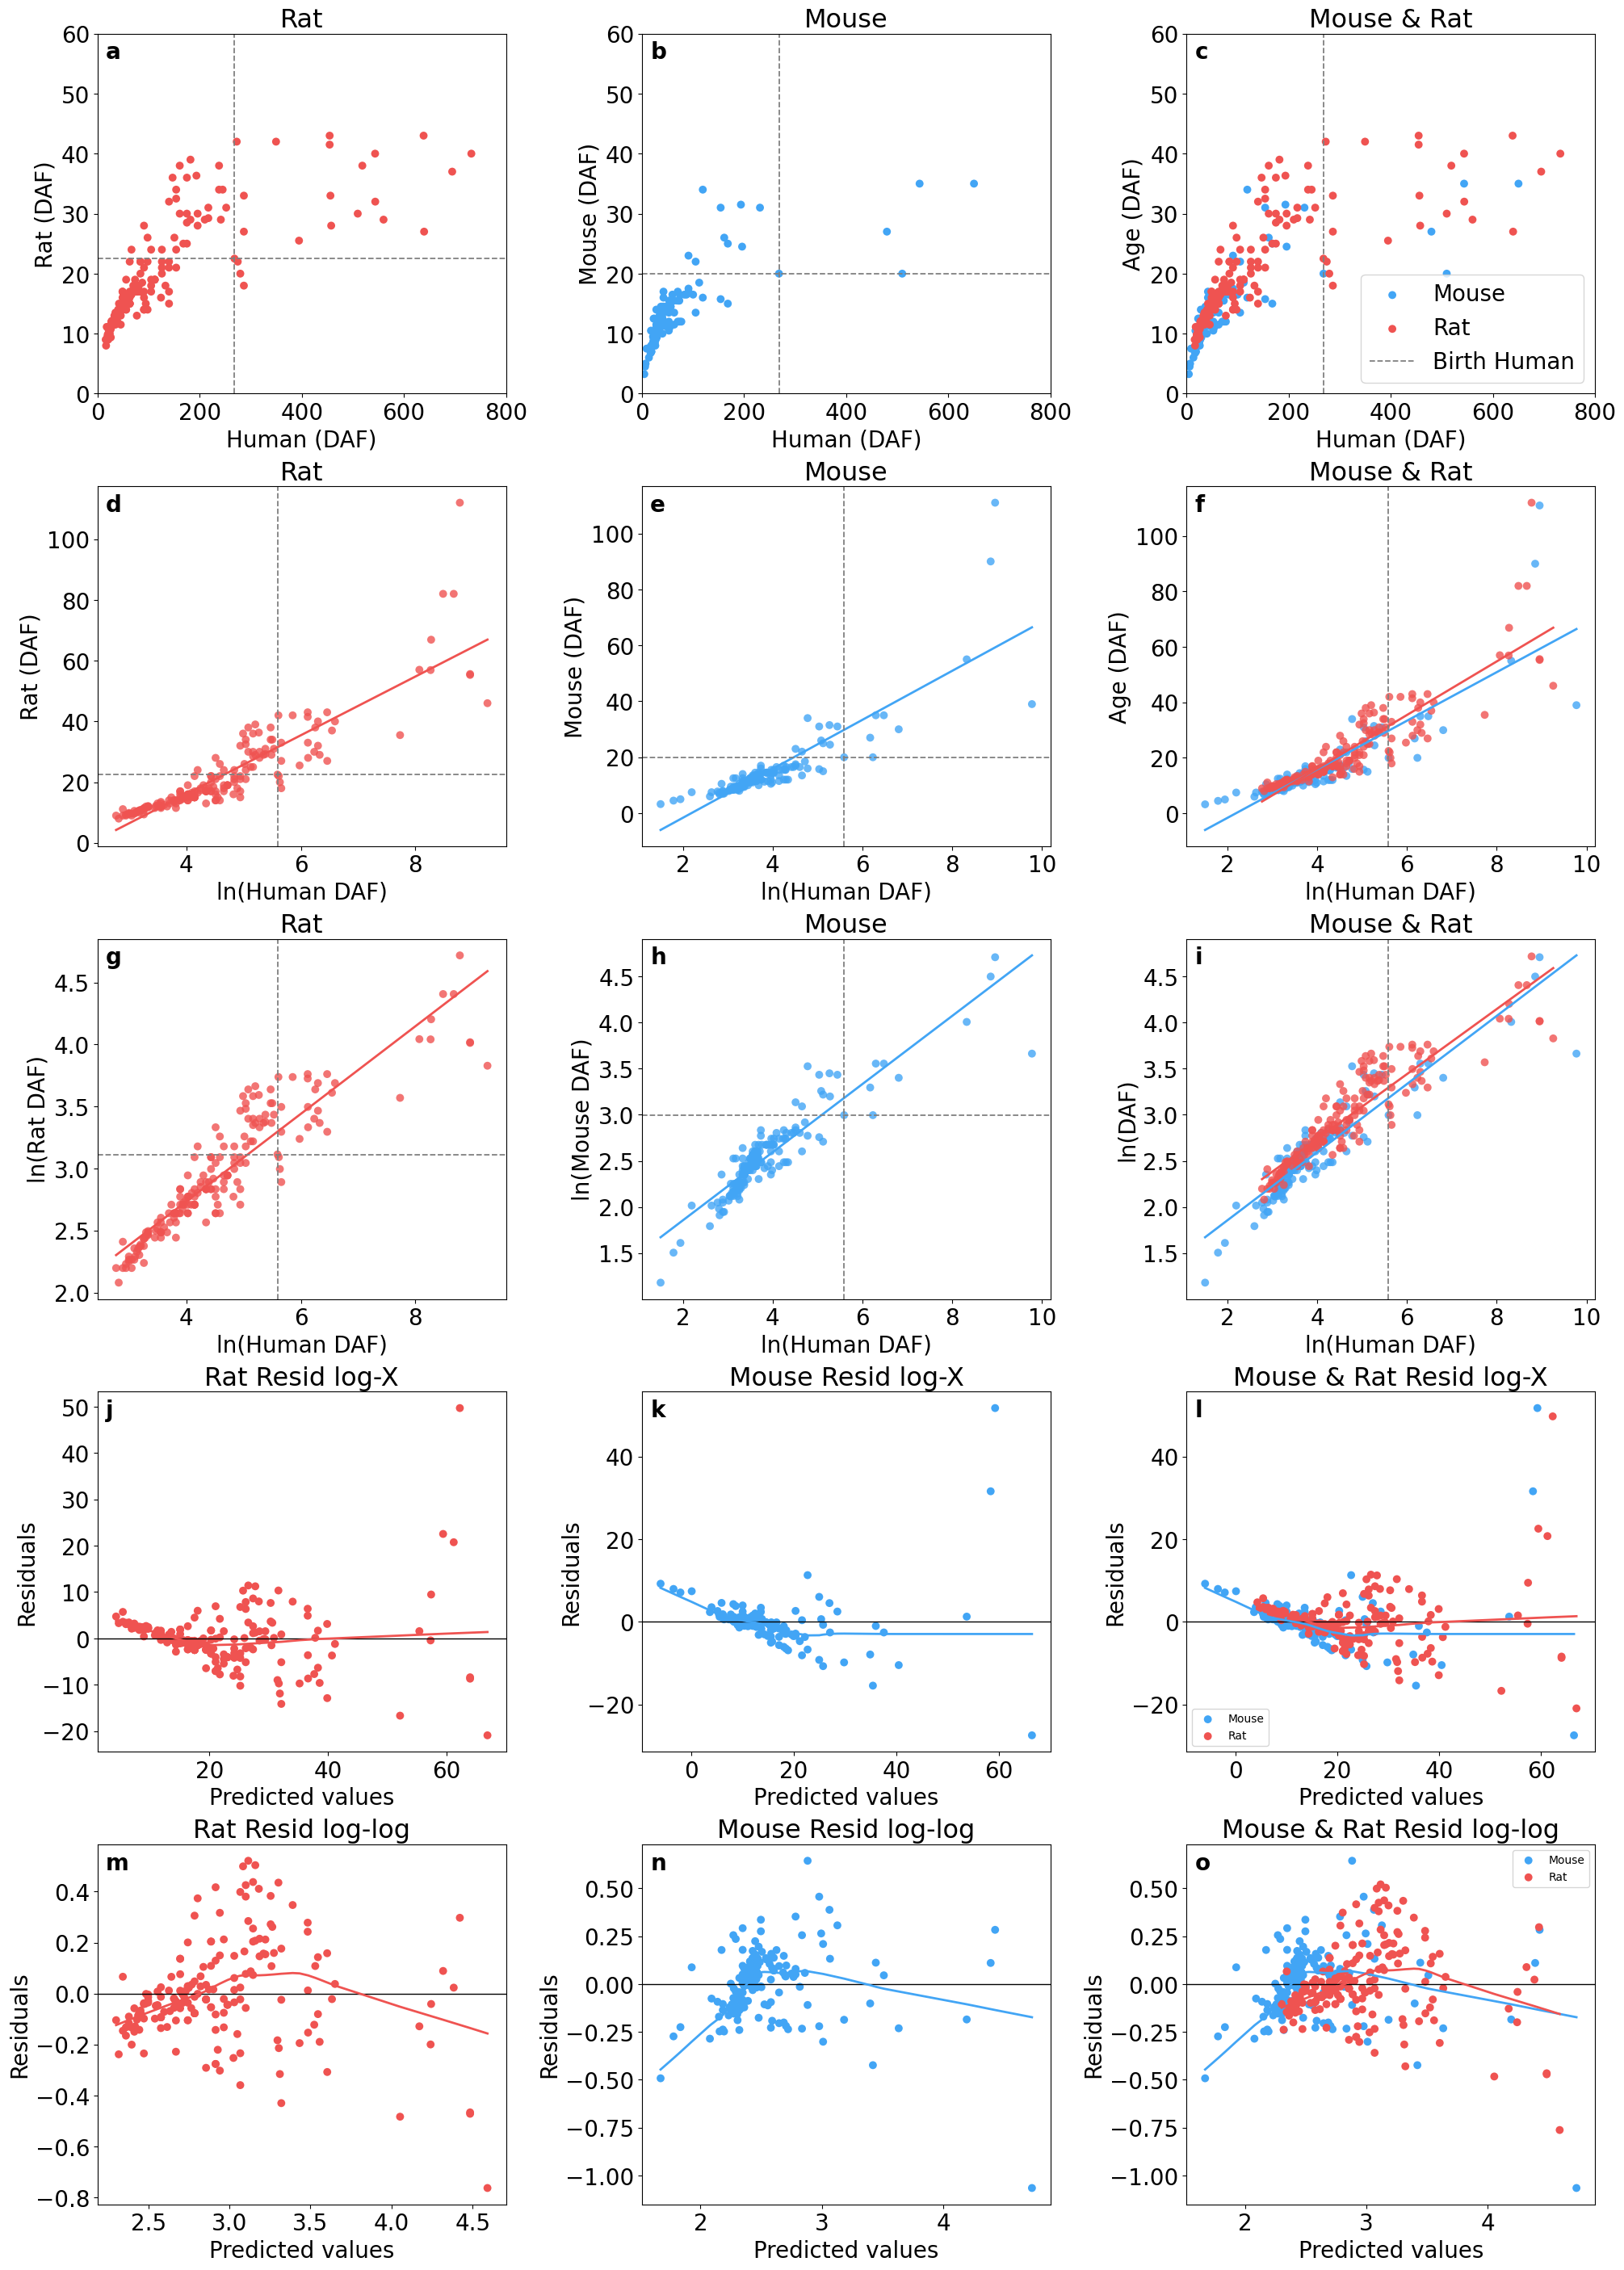

Panel saved as 'figures/panel1.tiff' and 'figures/panel1.pdf'


In [5]:

df = pd.read_csv('data/dataset_mrh_0.9.csv')
df_pivot = df.pivot_table(index='Parameter', columns='Species', values='DAF', aggfunc='mean').reset_index()


human_birth, mouse_birth, rat_birth = get_birth_values(df_pivot)

human = df_pivot['Human']
mouse = df_pivot['Mouse']
rat = df_pivot['Rat']
ln_human = np.log(human)
ln_mouse = np.log(mouse)
ln_rat = np.log(rat)

MARKER_SIZE = 50  # consistent marker size across all plots

def clean_xy(x, y):
    mask = ~np.isnan(x) & ~np.isnan(y)
    return x[mask].values, y[mask].values

def reg_stats(x, y):
    slope, intercept, r, _, _ = stats.linregress(x, y)
    return slope, intercept, r**2

def residuals_from_fit(x, y):
    slope, intercept, _, _, _ = stats.linregress(x, y)
    fitted = slope * x + intercept
    return fitted, y - fitted

def plot_single_reg(ax, x, y, color, title, xlabel, ylabel, birth_x,birth_y, with_line=True, show_legend=True):
    df_plot = pd.DataFrame({'x': x, 'y': y})
    if with_line:
        sns.regplot(
            data=df_plot, x='x', y='y', color=color, ci=None,
            scatter_kws={'s': MARKER_SIZE, 'edgecolors': 'none'}, line_kws={'linewidth': 2},
            ax=ax
        )
    else:
        sns.scatterplot(data=df_plot, x='x', y='y', color=color, s=MARKER_SIZE, edgecolor='none', ax=ax)
    ax.axvline(x=birth_x, color='gray', linestyle='--', linewidth=1.3)
    ax.axhline(y=birth_y, color='gray', linestyle='--', linewidth=1.3)
    ax.set_title(title, fontsize=FS_TITLE)
    ax.set_xlabel(xlabel, fontsize=FS_LABEL)
    ax.set_ylabel(ylabel, fontsize=FS_LABEL)
    ax.tick_params(axis='both', labelsize=FS_TICK)

def plot_both_reg(ax, x_m, y_m, x_r, y_r, title, xlabel, ylabel, birth_x, with_line=True, show_legend=True):
    if with_line:
        sns.regplot(
            data=pd.DataFrame({'x': x_m, 'y': y_m}), x='x', y='y', color=colors['Mouse'], ci=None,
            scatter_kws={'s': MARKER_SIZE, 'edgecolors': 'none'}, line_kws={'linewidth': 2},
            label='Mouse', ax=ax
        )
        sns.regplot(
            data=pd.DataFrame({'x': x_r, 'y': y_r}), x='x', y='y', color=colors['Rat'], ci=None,
            scatter_kws={'s': MARKER_SIZE, 'edgecolors': 'none'}, line_kws={'linewidth': 2},
            label='Rat', ax=ax
        )
    else:
        sns.scatterplot(x=x_m, y=y_m, color=colors['Mouse'], s=MARKER_SIZE, edgecolor='none', ax=ax, label='Mouse')
        sns.scatterplot(x=x_r, y=y_r, color=colors['Rat'], s=MARKER_SIZE, edgecolor='none', ax=ax, label='Rat')
    ax.axvline(x=birth_x, color='gray', linestyle='--', linewidth=1.3, label='Birth Human')
    ax.set_title(title, fontsize=FS_TITLE)
    ax.set_xlabel(xlabel, fontsize=FS_LABEL)
    ax.set_ylabel(ylabel, fontsize=FS_LABEL)
    ax.tick_params(axis='both', labelsize=FS_TICK)
    if show_legend:
        ax.legend(fontsize=FS_LEGEND)

def plot_residual(ax, x, y, color, title):
    fitted, resid = residuals_from_fit(x, y)
    sns.scatterplot(x=fitted, y=resid, color=color, s=MARKER_SIZE, edgecolor='none', ax=ax)
    ax.axhline(0, color='black', linestyle='-', linewidth=1)
    
    loess = sm.nonparametric.lowess(resid, fitted, frac=0.8)
    ax.plot(loess[:, 0], loess[:, 1], color=color, linewidth=2)
    ax.set_title(title, fontsize=FS_TITLE)
    ax.set_xlabel('Predicted values', fontsize=FS_LABEL)
    ax.set_ylabel('Residuals', fontsize=FS_LABEL)
    ax.tick_params(axis='both', labelsize=FS_TICK)

def plot_residual_both(ax, x_m, y_m, x_r, y_r, title):
    fitted_m, resid_m = residuals_from_fit(x_m, y_m)
    fitted_r, resid_r = residuals_from_fit(x_r, y_r)

    sns.scatterplot(x=fitted_m, y=resid_m, color=colors['Mouse'], s=MARKER_SIZE, edgecolor='none', ax=ax, label='Mouse')
    sns.scatterplot(x=fitted_r, y=resid_r, color=colors['Rat'], s=MARKER_SIZE, edgecolor='none', ax=ax, label='Rat')
    ax.axhline(0, color='black', linestyle='-', linewidth=1)

    loess_m = sm.nonparametric.lowess(resid_m, fitted_m, frac=0.8)
    loess_r = sm.nonparametric.lowess(resid_r, fitted_r, frac=0.8)
    ax.plot(loess_m[:, 0], loess_m[:, 1], color=colors['Mouse'], linewidth=2)
    ax.plot(loess_r[:, 0], loess_r[:, 1], color=colors['Rat'], linewidth=2)

    ax.set_title(title, fontsize=FS_TITLE)
    ax.set_xlabel('Predicted values', fontsize=FS_LABEL)
    ax.set_ylabel('Residuals', fontsize=FS_LABEL)
    ax.tick_params(axis='both', labelsize=FS_TICK)

def add_panel_letters(axes, start_letter='a'):
    start = ord(start_letter)
    for i, ax in enumerate(axes):
        ax.text(
            0.02, 0.98, chr(start + i),
            transform=ax.transAxes, ha='left', va='top',
            fontsize=FS_PANEL, fontweight='bold'
        )

# Clean pairs
x_h_r, y_r_raw = clean_xy(human, rat)
x_h_m, y_m_raw = clean_xy(human, mouse)
x_lh_r_raw, y_lh_r_raw = clean_xy(ln_human, rat)
x_lh_m_raw, y_lh_m_raw = clean_xy(ln_human, mouse)
x_lh_lr, y_lh_lr = clean_xy(ln_human, ln_rat)
x_lh_lm, y_lh_lm = clean_xy(ln_human, ln_mouse)

# Main layout: 5 rows x 3 cols (Rat | Mouse | Mouse+Rat overlap)
fig = plt.figure(figsize=(20, 28), constrained_layout=True)
gs = gridspec.GridSpec(5, 3, figure=fig)

ax_reg = [[fig.add_subplot(gs[r, c]) for c in range(3)] for r in range(3)]
ax_res_r_logx = fig.add_subplot(gs[3, 0])
ax_res_m_logx = fig.add_subplot(gs[3, 1])
ax_res_both_logx = fig.add_subplot(gs[3, 2])
ax_res_r_loglog = fig.add_subplot(gs[4, 0])
ax_res_m_loglog = fig.add_subplot(gs[4, 1])
ax_res_both_loglog = fig.add_subplot(gs[4, 2])

# Row 0: raw scale (labels shown)
plot_single_reg(ax_reg[0][0], x_h_r, y_r_raw, colors['Rat'], 'Rat', 'Human (DAF)', 'Rat (DAF)', human_birth,rat_birth, with_line=False, show_legend=False)
plot_single_reg(ax_reg[0][1], x_h_m, y_m_raw, colors['Mouse'], 'Mouse', 'Human (DAF)', 'Mouse (DAF)', human_birth, mouse_birth, with_line=False, show_legend=False)
plot_both_reg(ax_reg[0][2], x_h_m, y_m_raw, x_h_r, y_r_raw, 'Mouse & Rat', 'Human (DAF)', 'Age (DAF)', human_birth, with_line=False, show_legend=True)

ax_reg[0][0].set_xlim(0, 800)
ax_reg[0][1].set_xlim(0, 800)
ax_reg[0][2].set_xlim(0, 800)
ax_reg[0][0].set_ylim(0, 60)
ax_reg[0][1].set_ylim(0, 60)
ax_reg[0][2].set_ylim(0, 60)

# Row 1: ln(Human) vs raw Age (no labels)
plot_single_reg(ax_reg[1][0], x_lh_r_raw, y_lh_r_raw, colors['Rat'], 'Rat', 'ln(Human DAF)', 'Rat (DAF)', np.log(human_birth),rat_birth)
plot_single_reg(ax_reg[1][1], x_lh_m_raw, y_lh_m_raw, colors['Mouse'], 'Mouse', 'ln(Human DAF)', 'Mouse (DAF)', np.log(human_birth), mouse_birth)
plot_both_reg(ax_reg[1][2], x_lh_m_raw, y_lh_m_raw, x_lh_r_raw, y_lh_r_raw, 'Mouse & Rat', 'ln(Human DAF)', 'Age (DAF)', np.log(human_birth), show_legend=False)

# Row 2: ln(Human) vs ln(Age) (no labels)
plot_single_reg(ax_reg[2][0], x_lh_lr, y_lh_lr, colors['Rat'], 'Rat', 'ln(Human DAF)', 'ln(Rat DAF)', np.log(human_birth), np.log(rat_birth))
plot_single_reg(ax_reg[2][1], x_lh_lm, y_lh_lm, colors['Mouse'], 'Mouse', 'ln(Human DAF)', 'ln(Mouse DAF)', np.log(human_birth), np.log(mouse_birth))
plot_both_reg(ax_reg[2][2], x_lh_lm, y_lh_lm, x_lh_lr, y_lh_lr, 'Mouse & Rat', 'ln(Human DAF)', 'ln(DAF)', np.log(human_birth), show_legend=False)

# Row 3: residuals log-X
plot_residual(ax_res_r_logx, x_lh_r_raw, y_lh_r_raw, colors['Rat'], 'Rat Resid log-X')
plot_residual(ax_res_m_logx, x_lh_m_raw, y_lh_m_raw, colors['Mouse'], 'Mouse Resid log-X')
plot_residual_both(ax_res_both_logx, x_lh_m_raw, y_lh_m_raw, x_lh_r_raw, y_lh_r_raw, 'Mouse & Rat Resid log-X')

# Row 4: residuals log-log
plot_residual(ax_res_r_loglog, x_lh_lr, y_lh_lr, colors['Rat'], 'Rat Resid log-log')
plot_residual(ax_res_m_loglog, x_lh_lm, y_lh_lm, colors['Mouse'], 'Mouse Resid log-log')
plot_residual_both(ax_res_both_loglog, x_lh_lm, y_lh_lm, x_lh_lr, y_lh_lr, 'Mouse & Rat Resid log-log')

# Add lowercase panel letters
all_axes = [
    *[ax for row in ax_reg for ax in row],
    ax_res_r_logx, ax_res_m_logx, ax_res_both_logx,
    ax_res_r_loglog, ax_res_m_loglog, ax_res_both_loglog,
]
add_panel_letters(all_axes, start_letter='a')

# Evita problemas de fuentes en revistas/editoriales
mpl.rcParams['pdf.fonttype'] = 42
mpl.rcParams['ps.fonttype'] = 42

# Guardar en PDF vectorial
plt.savefig("figures/panel1.pdf", bbox_inches="tight", pad_inches=0.02)

# Guardar en TIFF alta resolución
plt.savefig(
    'figures/panel1.tiff',
    dpi=TIFF_DPI,
    bbox_inches='tight'
)
plt.show()

print("Panel saved as 'figures/panel1.tiff' and 'figures/panel1.pdf'")


In [6]:
# Tests diagnósticos (se conservan + log persistente por notebook)



NOTEBOOK_KEY = 'panel1_0.4'
NOTEBOOK_TITLE = 'Panel 1 - Diagnosticos de Modelos'


def diagnostic_tests(x, y, label):
    """Returns Breusch-Pagan and RESET test results for simple OLS."""
    mask = ~np.isnan(x) & ~np.isnan(y)
    x_c, y_c = x[mask], y[mask]
    X = sm.add_constant(x_c)
    model = sm.OLS(y_c, X).fit()

    bp_lm, bp_p, _, _ = het_breuschpagan(model.resid, model.model.exog)
    reset = linear_reset(model, power=2, use_f=True)

    return {
        'Transformation': label,
        'BP stat': round(bp_lm, 3),
        'BP p': round(bp_p, 4),
        'Heterosc?': 'YES' if bp_p < 0.05 else 'no',
        'RESET F': round(reset.statistic, 3),
        'RESET p': round(reset.pvalue, 4),
        'Non-linear?': 'YES' if reset.pvalue < 0.05 else 'no',
    }



dat_rm = df_pivot[['Rat', 'Mouse']].dropna()

cases = {
    'Mouse': [
        ('Raw  (Human -> Mouse)', x_h_m.astype(float), y_m_raw.astype(float)),
        ('log-X  (ln(Human) -> Mouse)', x_lh_m_raw.astype(float), y_lh_m_raw.astype(float)),
        ('log-log (ln(Human) -> ln(Mouse))', x_lh_lm.astype(float), y_lh_lm.astype(float)),
    ],
    'Rat': [
        ('Raw  (Human -> Rat)', x_h_r.astype(float), y_r_raw.astype(float)),
        ('log-X  (ln(Human) -> Rat)', x_lh_r_raw.astype(float), y_lh_r_raw.astype(float)),
        ('log-log (ln(Human) -> ln(Rat))', x_lh_lr.astype(float), y_lh_lr.astype(float)),
    ],
    'Rat vs Mouse': [
        ('Raw  (Rat -> Mouse)', dat_rm['Rat'].astype(float), dat_rm['Mouse'].astype(float)),
    ],
}



for species, pairs in cases.items():
    rows = [diagnostic_tests(x, y, lbl) for lbl, x, y in pairs]
    df_diag = pd.DataFrame(rows).set_index('Transformation')

    print(f'\n{'='*70}')
    print(f'  {species} - Heteroscedasticity (Breusch-Pagan) & Linearity (RESET)')
    print(f'{'='*70}')
    print(df_diag.to_string())

    # Save diagnostics table for this species as CSV using a relative path string (no os/pathlib)
    csv_path = 'results/panel1_diagnostics.csv'
    try:
        df_diag.to_csv(csv_path)
        print(f"Saved diagnostics for {species} to {csv_path}")
    except Exception as e:
        print(f"Could not save diagnostics for {species} to {csv_path}: {e}")


print('\nInterpretation: p < 0.05 -> significant heteroscedasticity / non-linearity.')



  Mouse - Heteroscedasticity (Breusch-Pagan) & Linearity (RESET)
                                  BP stat  BP p Heterosc?  RESET F  RESET p Non-linear?
Transformation                                                                         
Raw  (Human -> Mouse)             149.819   0.0       YES  549.985      0.0         YES
log-X  (ln(Human) -> Mouse)        63.217   0.0       YES   31.996      0.0         YES
log-log (ln(Human) -> ln(Mouse))   37.465   0.0       YES   53.014      0.0         YES
Saved diagnostics for Mouse to results/panel1_diagnostics.csv

  Rat - Heteroscedasticity (Breusch-Pagan) & Linearity (RESET)
                                BP stat  BP p Heterosc?  RESET F  RESET p Non-linear?
Transformation                                                                       
Raw  (Human -> Rat)             106.356   0.0       YES  136.748   0.0000         YES
log-X  (ln(Human) -> Rat)        32.910   0.0       YES   12.473   0.0005         YES
log-log (ln(Human) -> ln